# SNAP graph: exploratory data analysis

Structural EDA of a [Stanford SNAP](https://snap.stanford.edu/data/) edge list. Set the file in the config cell
(or via the `SNAP_FILE` environment variable); the rest adapts to directed / undirected graphs.
Expensive statistics (clustering, path lengths) are sampled on large graphs.

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

NB_DIR = Path.cwd()
SNAP_DIR = NB_DIR.parent if NB_DIR.name == "notebooks" else NB_DIR
sys.path.insert(0, str(SNAP_DIR))
from snap_loader import DATA_DIR, load_edgelist

DATA_FILE = DATA_DIR / os.environ.get("SNAP_FILE", "facebook_combined.txt.gz")
SEED = 0
SAMPLE_NODES = 2000          # nodes sampled for clustering estimates
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (6, 4), "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and header

In [2]:
edges, meta = load_edgelist(DATA_FILE)
print(DATA_FILE.name)
print("\n".join(meta["lines"]))
directed = bool(meta["directed"])
print("\ndirected:", directed, "| extra columns:", [c for c in edges.columns if c not in ("src", "dst")])
edges.head()

facebook_combined.txt.gz


directed: False | extra columns: []


,src,dst
0,0,1
1,0,2
2,0,3
3,0,4
4,0,5


## 2. Basic statistics and data quality

In [3]:
src, dst = edges["src"].to_numpy(), edges["dst"].to_numpy()
ids = np.unique(np.concatenate([src, dst]))
n, m_raw = len(ids), len(edges)
self_loops = int((src == dst).sum())
pair = np.column_stack([src, dst]) if directed else np.sort(np.column_stack([src, dst]), axis=1)
dup = int(pd.DataFrame(pair).duplicated().sum())

# compact node ids 0..n-1 and a deduplicated, loop-free edge table
idx = pd.Series(np.arange(n), index=ids)
e = pd.DataFrame(pair, columns=["u", "v"]).drop_duplicates()
e = e[e.u != e.v]
e["u"], e["v"] = idx[e.u].to_numpy(), idx[e.v].to_numpy()
m = len(e)
possible = n * (n - 1) / (1 if directed else 2)

stats = pd.Series({
    "nodes": n, "edges (raw rows)": m_raw, "edges (unique, no loops)": m,
    "self loops": self_loops, "duplicate edges": dup,
    "declared nodes": meta["nodes"], "declared edges": meta["edges"],
    "node id min / max": f"{ids.min()} / {ids.max()}",
    "id gaps (max id + 1 - nodes)": int(ids.max()) + 1 - n,
    "density": m / possible, "mean degree": (1 if directed else 2) * m / n,
})
stats.to_frame("value")

,value
nodes,4039
edges (raw rows),88234
"edges (unique, no loops)",88234
self loops,0
duplicate edges,0
declared nodes,None
declared edges,None
node id min / max,0 / 4038
id gaps (max id + 1 - nodes),0
density,0.01082


In [4]:
A = sp.coo_matrix((np.ones(m), (e.u, e.v)), shape=(n, n)).tocsr()
if directed:
    recip = A.multiply(A.T).nnz / A.nnz
    print(f"reciprocity (share of edges with reverse edge): {recip:.3f}")
else:
    A = ((A + A.T) > 0).astype(float).tocsr()

## 3. Degree distribution

,degree
count,4039.000000
mean,43.691013
std,52.420605
min,1.000000
50%,25.000000
90%,112.200000
99%,199.620000
max,1045.000000
zero-degree nodes,0.000000


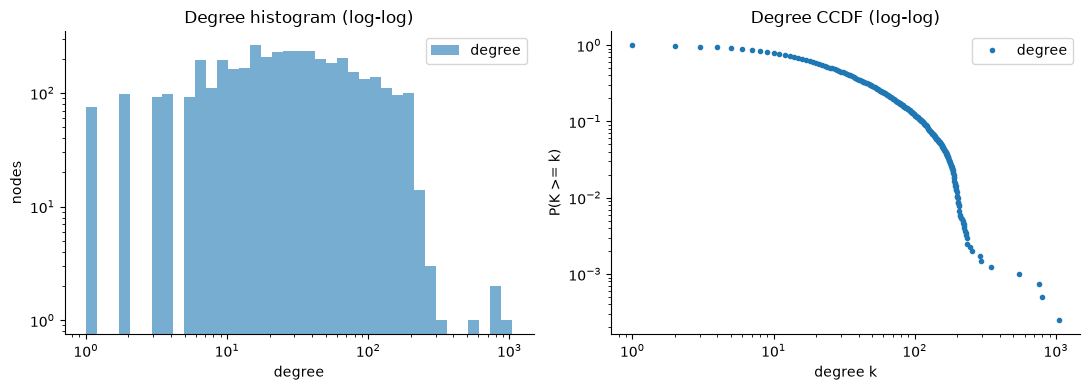

In [5]:
if directed:
    deg = {"in": np.asarray(A.sum(0)).ravel(), "out": np.asarray(A.sum(1)).ravel()}
else:
    deg = {"degree": np.asarray(A.sum(1)).ravel()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, d in deg.items():
    axes[0].hist(d, bins=np.logspace(0, np.log10(max(d.max(), 2)), 40), alpha=0.6, label=name)
    vals, counts = np.unique(d[d > 0], return_counts=True)
    ccdf = 1 - np.cumsum(counts) / counts.sum() + counts / counts.sum()
    axes[1].loglog(vals, ccdf, ".", label=name)
axes[0].set(xscale="log", yscale="log", xlabel="degree", ylabel="nodes", title="Degree histogram (log-log)")
axes[1].set(xlabel="degree k", ylabel="P(K >= k)", title="Degree CCDF (log-log)")
for a in axes:
    a.legend()
plt.tight_layout()

summary = pd.DataFrame({k: pd.Series(d).describe(percentiles=[.5, .9, .99]) for k, d in deg.items()})
summary.loc["zero-degree nodes"] = [int((d == 0).sum()) for d in deg.values()]
summary

In [6]:
# heavy-tail check: share of degree mass held by the top 1% / 10% of nodes, and the hubs
d = deg.get("degree", deg.get("out"))
srt = np.sort(d)[::-1]
for q in (0.01, 0.10):
    print(f"top {q:.0%} of nodes hold {srt[: max(1, int(q * n))].sum() / srt.sum():.1%} of degree mass")
pd.DataFrame({"node id": ids[np.argsort(-d)[:10]], "degree": srt[:10]})

top 1% of nodes hold 6.3% of degree mass
top 10% of nodes hold 37.3% of degree mass


,node id,degree
0,107,1045.0
1,1684,792.0
2,1912,755.0
3,3437,547.0
4,0,347.0
5,2543,294.0
6,2347,291.0
7,1888,254.0
8,1800,245.0
9,1663,235.0


## 4. Connected components

In [7]:
rows = {}
for kind in (["weak", "strong"] if directed else ["weak"]):
    k, lab = connected_components(A, directed=directed, connection=kind)
    sizes = np.bincount(lab)
    rows[kind] = {"components": k, "largest": sizes.max(), "largest share": sizes.max() / n,
                  "singletons": int((sizes == 1).sum())}
    if kind == "weak":
        wlab, wsizes = lab, sizes
pd.DataFrame(rows).T

,components,largest,largest share,singletons
weak,1.0,4039.0,1.0,0.0


In [8]:
lcc_nodes = np.flatnonzero(wlab == wsizes.argmax())
A_lcc = A[lcc_nodes][:, lcc_nodes]
U = nx.Graph(nx.from_scipy_sparse_array(A_lcc))   # undirected view of the largest component
print("largest weakly connected component:", U.number_of_nodes(), "nodes,", U.number_of_edges(), "undirected edges")

largest weakly connected component: 4039 nodes, 88234 undirected edges


## 5. Clustering and triangles (sampled)

average clustering (sample of 2000): 0.6053


global transitivity: 0.5192


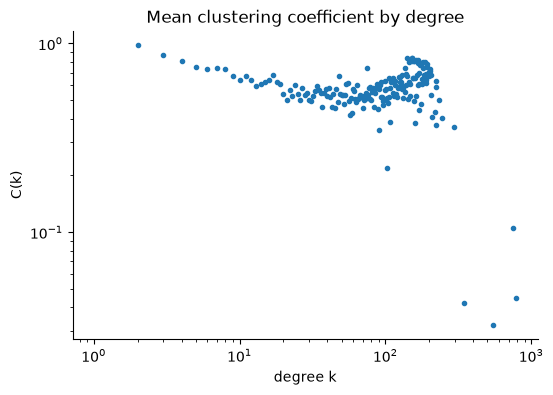

In [9]:
sample = rng.choice(U.number_of_nodes(), size=min(SAMPLE_NODES, U.number_of_nodes()), replace=False)
cc = pd.Series(nx.clustering(U, nodes=[int(s) for s in sample]))
print(f"average clustering (sample of {len(sample)}): {cc.mean():.4f}")
if U.number_of_edges() <= 2_000_000:
    print(f"global transitivity: {nx.transitivity(U):.4f}")
deg_u = pd.Series(dict(U.degree()))
bydeg = pd.DataFrame({"k": deg_u[cc.index], "c": cc}).groupby("k").c.mean()
ax = bydeg.plot(style=".", logx=True, logy=True, figsize=(6, 4), title="Mean clustering coefficient by degree")
ax.set(xlabel="degree k", ylabel="C(k)");

## 6. Path lengths and degree correlation

mean shortest path ~ 3.71 | effective diameter (90th pct) ~ 5 | max seen 8
degree assortativity: 0.064


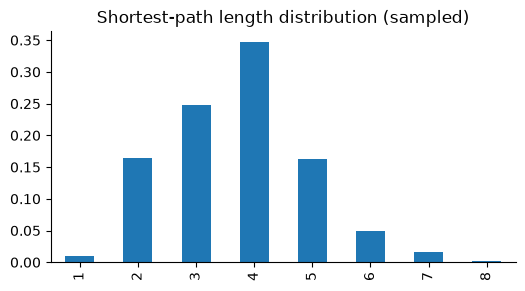

In [10]:
# BFS from sampled sources inside the largest component -> distance distribution
src_nodes = rng.choice(U.number_of_nodes(), size=min(100, U.number_of_nodes()), replace=False)
dist = np.concatenate([np.fromiter(nx.single_source_shortest_path_length(U, int(s)).values(), int) for s in src_nodes])
dist = dist[dist > 0]
print(f"mean shortest path ~ {dist.mean():.2f} | effective diameter (90th pct) ~ {np.percentile(dist, 90):.0f} | max seen {dist.max()}")
pd.Series(dist).value_counts(normalize=True).sort_index().plot.bar(figsize=(6, 3), title="Shortest-path length distribution (sampled)")
print(f"degree assortativity: {nx.degree_assortativity_coefficient(U):.3f}")

## 7. k-core structure

max core number (degeneracy): 115


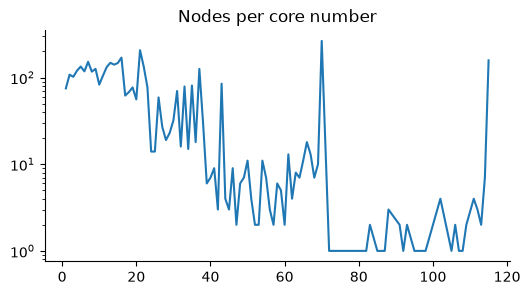

In [11]:
core = pd.Series(nx.core_number(U))
print("max core number (degeneracy):", core.max())
core.value_counts().sort_index().plot(logy=True, figsize=(6, 3), title="Nodes per core number");

## 8. Takeaways for graph generation / evaluation

ego-Facebook (`facebook_combined.txt.gz`): undirected, no `#` header, so directedness defaults to undirected.

- **Clean**: 4,039 nodes, 88,234 edges, ids 0-4038 contiguous, no self loops, duplicates, or isolated nodes.
- **Dense for a social graph**: density 1.1%, mean degree 43.7 (median 25), max 1,045 (node 107).
- **Moderate tail, not extreme**: top 1% of nodes hold 6.3% of degree mass, top 10% hold 37.3%. Hubs are the ego nodes (107, 1684, 1912, 3437, 0), an artefact of how the data was collected.
- **One component**: the graph is connected, so a generator that fragments it is wrong.
- **Strong clustering**: average clustering about 0.61, transitivity 0.52. This is the hardest property for degree-only generators (configuration model, Erdos-Renyi) to match.
- **Small world**: mean shortest path about 3.7, effective diameter 5, max 8.
- **Weak positive assortativity** (0.064) and a deep k-core (degeneracy 115), reflecting dense friend circles.

Checks a synthetic graph should preserve: size and density, degree CCDF (including hub share), clustering (global and by degree), connectivity, path lengths, assortativity, and the k-core profile.
